In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("C:/Users/Raginee/Downloads/Nettech_Employee_Performance_Dataset.csv")


In [3]:
df.head()


,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month
0,1,Aarav Sharma,IT,84.8,5.0,87.1,59000.0,2026-03
1,2,Priya Patel,Finance,94.0,5.0,88.3,53000.0,2026-03
2,3,Rahul Verma,IT,86.7,5.0,85.3,71000.0,2026-01
3,4,Sneha Joshi,HR,79.1,3.0,73.6,42000.0,2026-02
4,5,Rohan Mehta,Finance,80.1,5.0,85.3,61000.0,2026-01


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Sr No.              100 non-null    int64  
 1   Employee Name       100 non-null    str    
 2   Department          100 non-null    str    
 3   Attendance (%)      98 non-null     float64
 4   Projects Completed  99 non-null     float64
 5   Performance Score   99 non-null     float64
 6   Salary              99 non-null     float64
 7   Month               100 non-null    str    
dtypes: float64(4), int64(1), str(3)
memory usage: 6.4 KB


In [5]:
#Check missing value
df.isnull().sum()

Sr No.                0
Employee Name         0
Department            0
Attendance (%)        2
Projects Completed    1
Performance Score     1
Salary                1
Month                 0
dtype: int64

In [6]:
#Check duplicated
df.duplicated().sum()


np.int64(0)

In [7]:
#Remove duplicates:
df = df.drop_duplicates()

In [8]:
#Check numerical statistics:
df.describe()

,Sr No.,Attendance (%),Projects Completed,Performance Score,Salary
count,100.000000,98.000000,99.000000,99.000000,99.000000
mean,50.500000,87.038776,4.707071,85.456566,50636.363636
std,29.011492,6.109830,2.081270,8.306712,10367.191722
min,1.000000,73.100000,1.000000,64.300000,28000.000000
25%,25.750000,81.850000,3.000000,78.650000,42000.000000
50%,50.500000,86.500000,5.000000,86.200000,51000.000000
75%,75.250000,91.175000,6.000000,91.550000,58000.000000
max,100.000000,100.000000,11.000000,100.000000,72000.000000


In [9]:
df.isnull().sum()

Sr No.                0
Employee Name         0
Department            0
Attendance (%)        2
Projects Completed    1
Performance Score     1
Salary                1
Month                 0
dtype: int64

In [10]:
df["Attendance (%)"] = df["Attendance (%)"].fillna(df["Attendance (%)"].median())

In [11]:
df["Projects Completed"] = df["Projects Completed"].fillna(df["Projects Completed"].median())

In [12]:
df["Performance Score"] = df["Performance Score"].fillna(df["Performance Score"].median())

In [13]:
df["Salary"] = df['Salary'].fillna(df["Salary"].median())

In [14]:
#Check again
df.isnull().sum()

Sr No.                0
Employee Name         0
Department            0
Attendance (%)        0
Projects Completed    0
Performance Score     0
Salary                0
Month                 0
dtype: int64

In [15]:
#Check Data Types
df.dtypes

Sr No.                  int64
Employee Name             str
Department                str
Attendance (%)        float64
Projects Completed    float64
Performance Score     float64
Salary                float64
Month                     str
dtype: object

In [16]:
#Convert month to datetime
df["Month"] = pd.to_datetime(df["Month"])

In [17]:
#Check
df.dtypes

Sr No.                         int64
Employee Name                    str
Department                       str
Attendance (%)               float64
Projects Completed           float64
Performance Score            float64
Salary                       float64
Month                 datetime64[us]
dtype: object

In [18]:
#Basic Performance Analysis
#1. Avarage attendance
df["Attendance (%)"].mean()

np.float64(87.02799999999999)

In [19]:
#2. Average projects completed
df["Projects Completed"].mean()

np.float64(4.71)

In [20]:
#3. Avarage Performance Score
df["Performance Score"].mean()

np.float64(85.464)

In [21]:
#Highest and Lowest Performance
#1.Highest performance Score
df["Performance Score"].max()

np.float64(100.0)

In [22]:
#2. Lowest Performance Score
df["Performance Score"].min()


np.float64(64.3)

In [23]:
#Employee with highest performance
df.loc[df["Performance Score"].idxmax()]

Sr No.                                 58
Employee Name                Swati Mishra
Department                      Marketing
Attendance (%)                       93.8
Projects Completed                    6.0
Performance Score                   100.0
Salary                            42000.0
Month                 2026-03-01 00:00:00
Name: 57, dtype: object

In [24]:
#Employee with lowest performance
df.loc[df["Performance Score"].idxmin()]

Sr No.                                 79
Employee Name                   Amit Shah
Department                          Sales
Attendance (%)                       85.1
Projects Completed                    2.0
Performance Score                    64.3
Salary                            40000.0
Month                 2026-04-01 00:00:00
Name: 78, dtype: object

In [25]:
#Top Performers
#Find the top 10 employees:
top_performers = df.sort_values(
    by = "Performance Score",
    ascending = False
).head(10)
top_performers

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month
77,78,Kirti Mehta,Sales,82.3,8.0,100.0,48000.0,2026-01-01
95,96,Shweta Jain,Marketing,100.0,7.0,100.0,37000.0,2026-04-01
57,58,Swati Mishra,Marketing,93.8,6.0,100.0,42000.0,2026-03-01
43,44,Payal Verma,HR,91.0,7.0,99.1,32000.0,2026-06-01
51,52,Preeti Pawar,Sales,99.2,6.0,98.6,50000.0,2026-06-01
6,7,Aditya Kulkarni,IT,91.5,3.0,97.7,71000.0,2026-03-01
88,89,Hemant Joshi,Finance,100.0,8.0,97.6,53000.0,2026-05-01
33,34,Shreya Kulkarni,IT,85.4,5.0,97.0,64000.0,2026-06-01
13,14,Riya Chavan,IT,91.2,8.0,96.3,66000.0,2026-04-01
71,72,Reema Singh,Sales,100.0,4.0,96.1,45000.0,2026-03-01


In [26]:
#department wise Statistics
#Number of employees in each department
df["Department"].value_counts()

Department
IT           20
Finance      20
HR           20
Sales        20
Marketing    20
Name: count, dtype: int64

In [27]:
#Average Performance by department
df.groupby("Department")["Performance Score"].mean()

Department
Finance      84.175
HR           83.530
IT           86.000
Marketing    86.030
Sales        87.585
Name: Performance Score, dtype: float64

In [28]:
#Average attendance by department
df.groupby("Department")["Attendance (%)"].mean()

Department
Finance      86.810
HR           88.250
IT           85.580
Marketing    86.945
Sales        87.555
Name: Attendance (%), dtype: float64

In [29]:
#Avarage salary by department
df.groupby("Department")["Salary"].mean()

Department
Finance      53500.0
HR           40200.0
IT           63050.0
Marketing    46250.0
Sales        50200.0
Name: Salary, dtype: float64

In [30]:
#Complete department wise summary
#Useful for project report:
department_summary = df.groupby("Department").agg({
    "Attendance (%)":"mean",
    "Projects Completed":"mean",
    "Performance Score":"mean",
    "Salary":"mean"
}).round(2)
department_summary

,Attendance (%),Projects Completed,Performance Score,Salary
Department,,,,
Finance,86.81,4.15,84.18,53500.0
HR,88.25,5.00,83.53,40200.0
IT,85.58,4.25,86.00,63050.0
Marketing,86.94,5.25,86.03,46250.0
Sales,87.56,4.90,87.58,50200.0


In [31]:
#Best Performing Department
department_summary["Performance Score"].idxmax()

'Sales'

In [32]:
#And its score
department_summary["Performance Score"].max()

np.float64(87.58)

In [33]:
#Attendance Analysis
#employee with attendance above 90%

In [34]:
high_attendance = df[df["Attendance (%)"]>90]
high_attendance

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month
1,2,Priya Patel,Finance,94.0,5.0,88.3,53000.0,2026-03-01
6,7,Aditya Kulkarni,IT,91.5,3.0,97.7,71000.0,2026-03-01
8,9,Karan Shah,Sales,92.8,6.0,92.2,66000.0,2026-04-01
11,12,Isha Kapoor,Finance,92.4,5.0,95.7,63000.0,2026-04-01
13,14,Riya Chavan,IT,91.2,8.0,96.3,66000.0,2026-04-01
18,19,Sameer Khan,HR,91.4,5.0,89.7,36000.0,2026-03-01
21,22,Aditi Pawar,Finance,91.4,3.0,80.9,54000.0,2026-03-01
22,23,Yash Thakur,Finance,91.1,8.0,92.2,42000.0,2026-04-01
23,24,Simran Kaur,Sales,92.7,9.0,93.7,34000.0,2026-04-01
31,32,Komal Desai,HR,90.8,5.0,74.5,46000.0,2026-06-01


In [35]:
#Employee with attendance below 75%
low_attendance = df[df["Attendance (%)"]<75]
low_attendance

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month
75,76,Jyoti Mishra,IT,73.1,1.0,73.1,68000.0,2026-04-01


In [36]:
#Average attendance
df["Attendance (%)"].mean()

np.float64(87.02799999999999)

In [37]:
#Project Analysis
#Maximum projects completed
df["Projects Completed"].max()


np.float64(11.0)

In [38]:
#Employeed who completed the most projects
df[df["Projects Completed"]==df["Projects Completed"].max()]


,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month
59,60,Rupal Desai,Sales,98.2,11.0,90.4,56000.0,2026-02-01
81,82,Dinesh Verma,HR,95.5,11.0,89.4,50000.0,2026-06-01


In [39]:
#Average Projects Completed
df["Projects Completed"].mean()

np.float64(4.71)

In [40]:
#Salary Analysis
#Highest Salary
df["Salary"].max()

np.float64(72000.0)

In [41]:
#Lowest Salary
df["Salary"].min()

np.float64(28000.0)

In [42]:
#Avarage Salary
df["Salary"].mean()

np.float64(50640.0)

In [43]:
#Top 10 highest paid employees
top_salary =df.sort_values(
    by="Salary",
    ascending= False
).head(10)
top_salary

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month
79,80,Shruti Patil,IT,83.7,2.0,74.2,72000.0,2026-03-01
2,3,Rahul Verma,IT,86.7,5.0,85.3,71000.0,2026-01-01
6,7,Aditya Kulkarni,IT,91.5,3.0,97.7,71000.0,2026-03-01
5,6,Ananya Singh,IT,81.6,3.0,78.9,71000.0,2026-04-01
37,38,Mansi Mehta,IT,81.5,1.0,75.1,69000.0,2026-04-01
75,76,Jyoti Mishra,IT,73.1,1.0,73.1,68000.0,2026-04-01
62,63,Sameera Khan,IT,81.5,4.0,77.9,68000.0,2026-01-01
86,87,Sagar Singh,Finance,84.6,3.0,86.3,67000.0,2026-03-01
13,14,Riya Chavan,IT,91.2,8.0,96.3,66000.0,2026-04-01
8,9,Karan Shah,Sales,92.8,6.0,92.2,66000.0,2026-04-01


In [44]:
#Create Performance Category
#This is useful here
df["Performance Category"] = pd.cut(
    df["Performance Score"],
    bins=[0,59,74,89,100],
labels=["Needs Improvement","Average","Good","Excellent"]
)

In [45]:
#Check the result
df[["Employee Name","Performance Score","Performance Category"]].head(10)

,Employee Name,Performance Score,Performance Category
0,Aarav Sharma,87.1,Good
1,Priya Patel,88.3,Good
2,Rahul Verma,85.3,Good
3,Sneha Joshi,73.6,Average
4,Rohan Mehta,85.3,Good
5,Ananya Singh,78.9,Good
6,Aditya Kulkarni,97.7,Excellent
7,Neha Gupta,93.2,Excellent
8,Karan Shah,92.2,Excellent
9,Pooja Nair,83.4,Good


In [46]:
#Count Each Category:
df["Performance Category"].value_counts()

Performance Category
Good                 48
Excellent            39
Average              13
Needs Improvement     0
Name: count, dtype: int64

In [47]:
# Create Attendance Category

df["Attendance Category"] = pd.cut(
    df["Attendance (%)"],
    bins=[0, 74, 89, 100],
    labels=["Low", "Average", "Excellent"]
)


In [48]:
#Check
df["Attendance Category"].value_counts()

Attendance Category
Average      61
Excellent    38
Low           1
Name: count, dtype: int64

<Axes: xlabel='Department'>

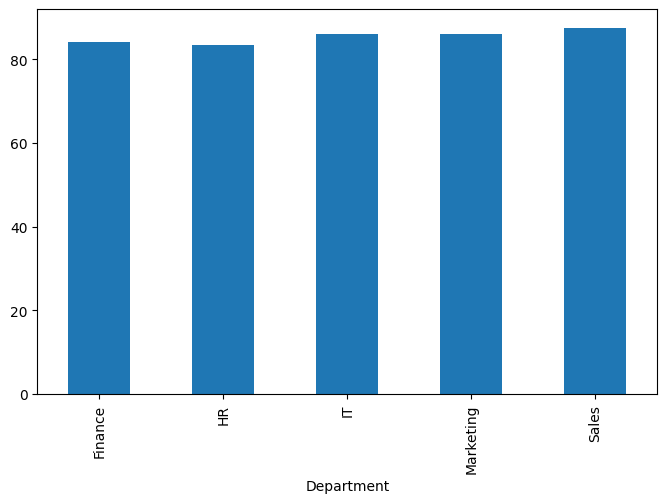

In [49]:
#Matplotlib-Department Performance Chhart
department_performance = df.groupby(
    "Department"
)["Performance Score"].mean()
plt.figure(figsize = (8,5))
department_performance.plot(kind="bar")

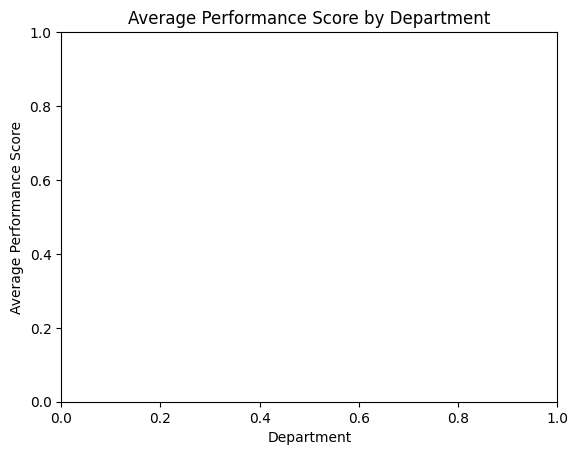

In [50]:
plt.title("Average Performance Score by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Score")
plt.xticks(rotation = 0)
plt.show()

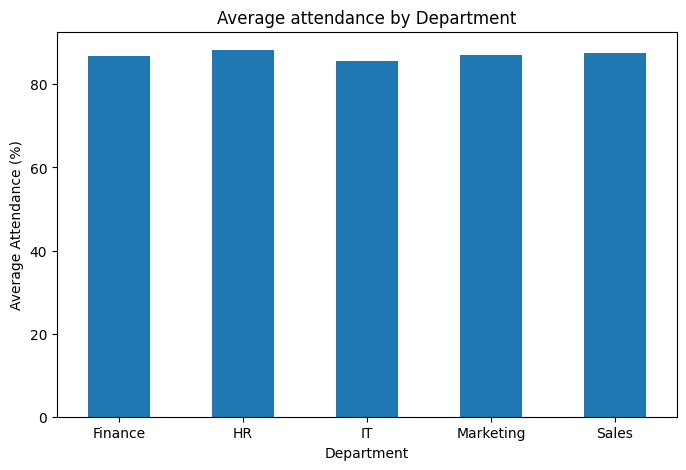

In [51]:
#Attendance by Department
department_attendance = df.groupby(
    "Department"
)["Attendance (%)"].mean()
plt.figure(figsize=(8,5))
department_attendance.plot(kind="bar")
plt.title("Average attendance by Department")
plt.xlabel("Department")
plt.ylabel("Average Attendance (%)")
plt.xticks(rotation = 0)
plt.show()

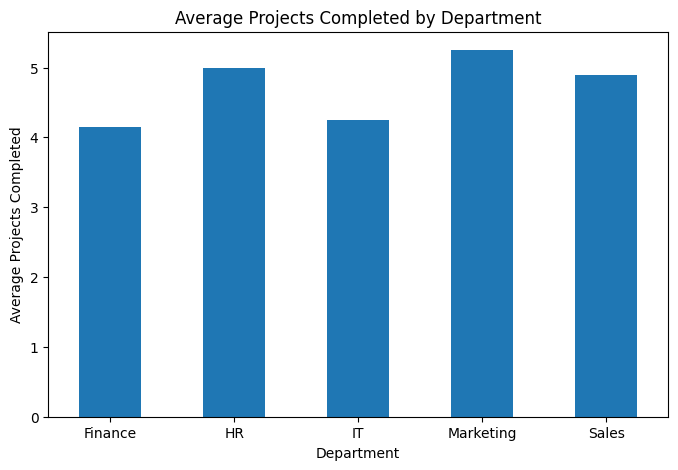

In [52]:
#Project by Department
department_projects = df.groupby(
    "Department"
)["Projects Completed"].mean()
plt.figure(figsize = (8,5))
department_projects.plot(kind = "bar")
plt.title("Average Projects Completed by Department")
plt.xlabel("Department")
plt.ylabel("Average Projects Completed")
plt.xticks(rotation = 0)
plt.show()

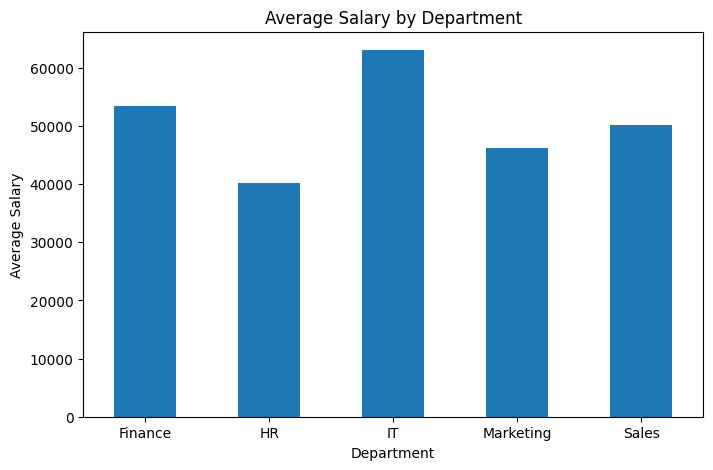

In [55]:
#Salary BY Department
department_salary = df.groupby("Department")["Salary"].mean()
plt.figure(figsize=(8,5))
department_salary.plot(kind = "bar")
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.xticks(rotation = 0)
plt.show()

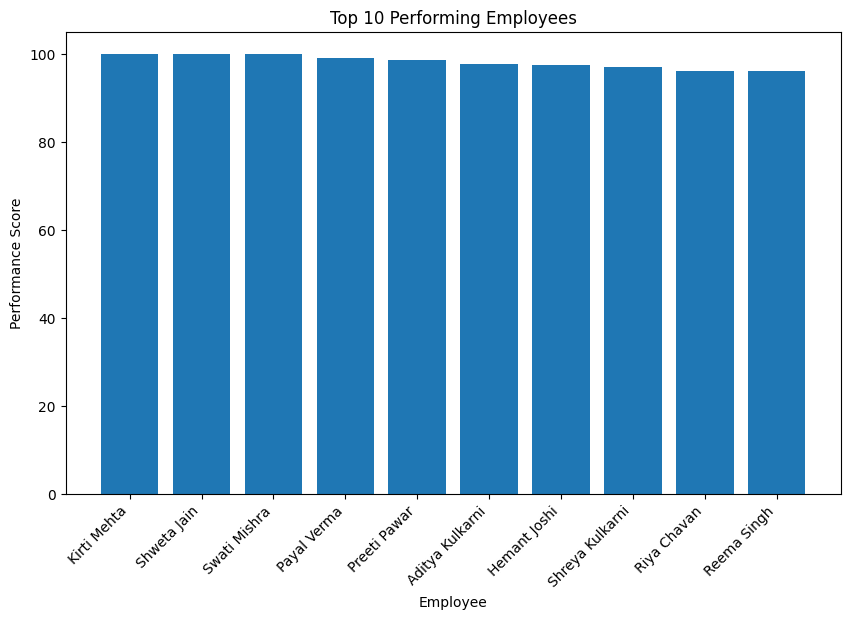

In [58]:
#Top 10 Performer Chart
top10 = df.sort_values("Performance Score",
                       ascending = False
                      ).head(10)
plt.figure(figsize = (10,6))
plt.bar(
    top10["Employee Name"],
    top10["Performance Score"]
)
plt.title("Top 10 Performing Employees")
plt.xlabel("Employee")
plt.ylabel("Performance Score")
plt.xticks(rotation = 45 , ha="right")
plt.show()

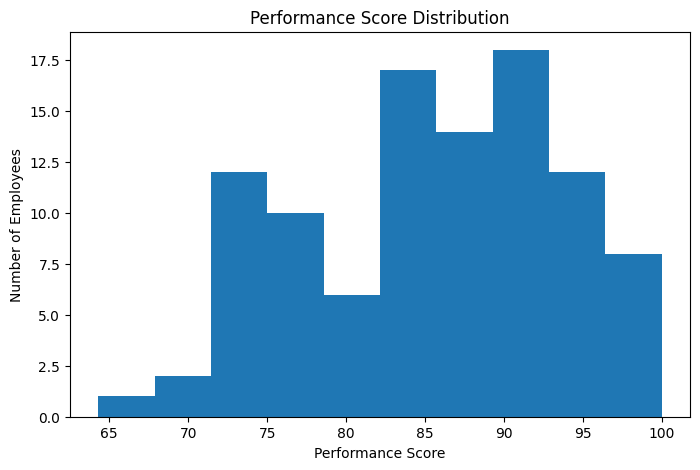

In [61]:
#Performance Score Distribution
plt.figure(figsize=(8,5))
plt.hist(df["Performance Score"],bins = 10)
plt.title("Performance Score Distribution")
plt.xlabel("Performance Score")
plt.ylabel("Number of Employees")
plt.show()

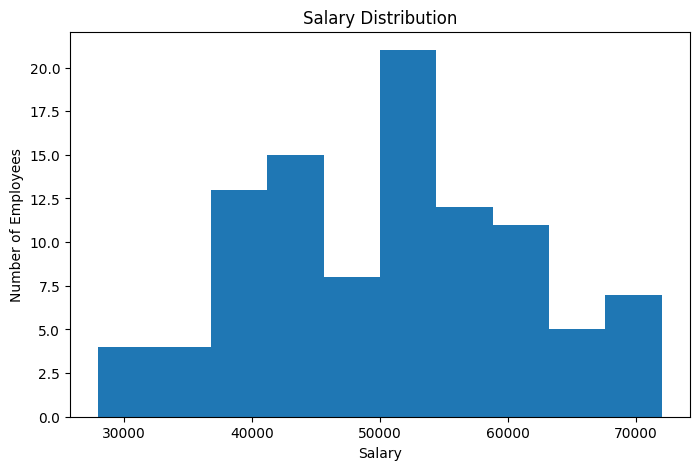

In [62]:
#Salary Distribution
plt.figure(figsize = (8,5))
plt.hist(df["Salary"], bins=10)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.show()

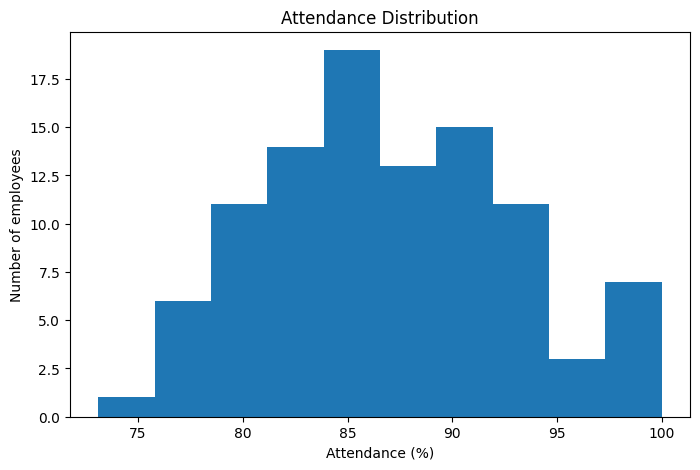

In [63]:
#Attendance Distribution
plt.figure(figsize=(8,5))
plt.hist(df["Attendance (%)"], bins =10)
plt.title("Attendance Distribution")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of employees")
plt.show()

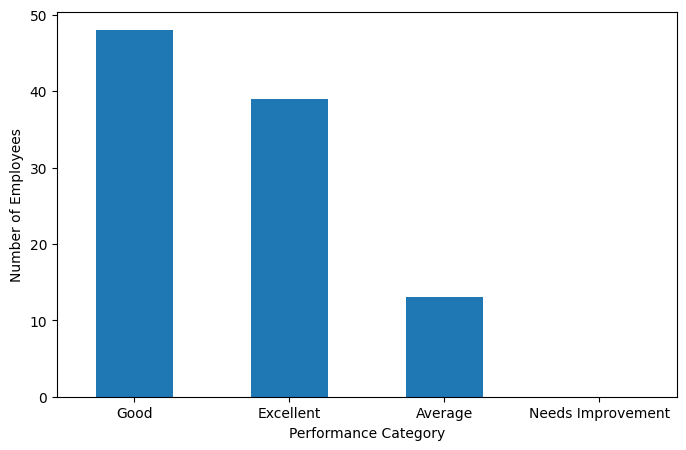

In [64]:
#Performance Category Chart
performance_counts = df["Performance Category"].value_counts()
plt.figure(figsize = (8,5))
performance_counts.plot(kind = "bar")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks(rotation = 0)
plt.show()

In [66]:
#Correlation Analysis
#For this Correlation Heatmap:
correlation = df[
    ["Attendance (%)",
     "Projects Completed",
     "Performance Score",
     "Salary"
    ]
    ].corr()
correlation


,Attendance (%),Projects Completed,Performance Score,Salary
Attendance (%),1.000000,0.474351,0.534442,-0.197901
Projects Completed,0.474351,1.000000,0.507495,-0.165238
Performance Score,0.534442,0.507495,1.000000,-0.007464
Salary,-0.197901,-0.165238,-0.007464,1.000000


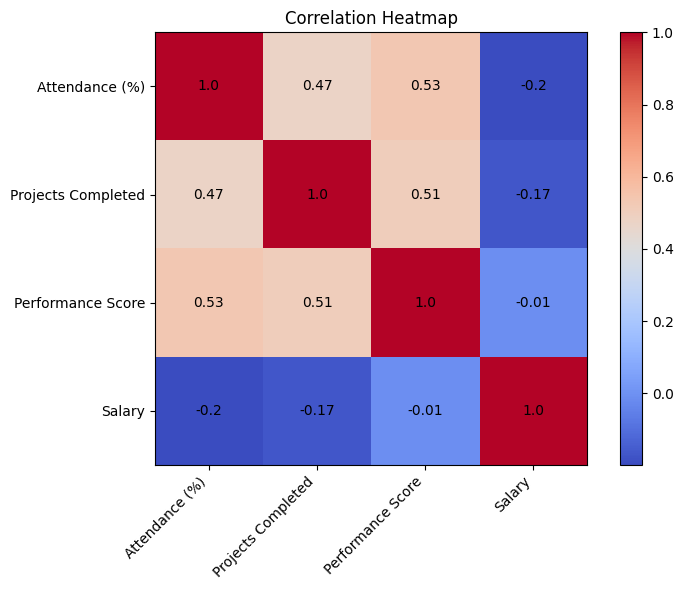

In [68]:
#Correlation Heatmap
#Using only Matplotlib:
plt.figure(figsize=(8,6))
plt.imshow(correlation,cmap = "coolwarm")
plt.colorbar()
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation = 45,
    ha = "right"
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)
plt.title("Correlation Heatmap")
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            round(correlation.iloc[i,j],2),
            ha="center",
            va="center"
        )
plt.tight_layout()
plt.show() 
        

In [70]:
#Monthly Analysis
#Since our dataset contains month column
monthly_performance = df.groupby("Month")["Performance Score"].mean()
monthly_performance

Month
2026-01-01    85.825000
2026-02-01    85.346154
2026-03-01    87.850000
2026-04-01    85.477273
2026-05-01    82.789474
2026-06-01    85.741667
Name: Performance Score, dtype: float64

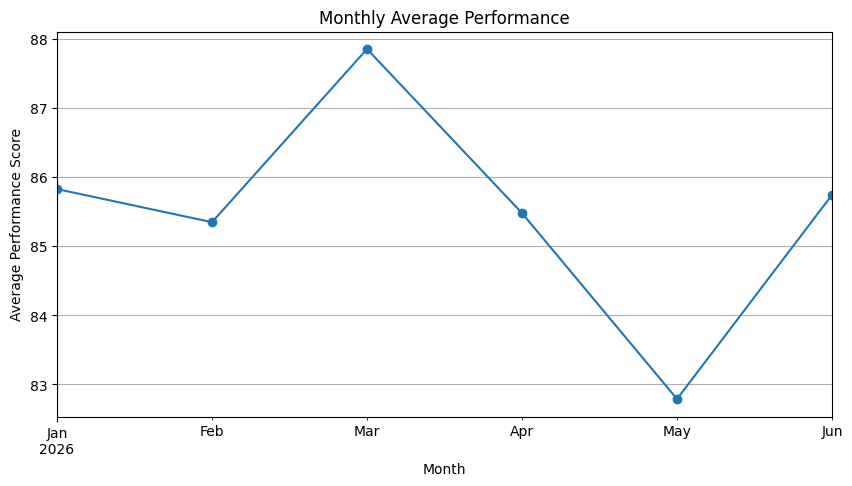

In [71]:
#plot it:
plt.figure(figsize=(10,5))
monthly_performance.plot(kind="line",marker="o")
plt.title("Monthly Average Performance")
plt.xlabel("Month")
plt.ylabel("Average Performance Score")
plt.grid()
plt.show()

In [72]:
#Monthly Employee Count
monthly_employee_count = df.groupby("Month").size()
monthly_employee_count

Month
2026-01-01    16
2026-02-01    13
2026-03-01    18
2026-04-01    22
2026-05-01    19
2026-06-01    12
dtype: int64

In [74]:
#Filter by department
#for eg:"IT":
it_employees = df[df["Department"]=="IT"]
it_employees

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month,Performance Category,Attendance Category
0,1,Aarav Sharma,IT,84.8,5.0,87.1,59000.0,2026-03-01,Good,Average
2,3,Rahul Verma,IT,86.7,5.0,85.3,71000.0,2026-01-01,Good,Average
5,6,Ananya Singh,IT,81.6,3.0,78.9,71000.0,2026-04-01,Good,Average
6,7,Aditya Kulkarni,IT,91.5,3.0,97.7,71000.0,2026-03-01,Excellent,Excellent
13,14,Riya Chavan,IT,91.2,8.0,96.3,66000.0,2026-04-01,Excellent,Excellent
16,17,Nikhil Patil,IT,85.3,7.0,92.0,56000.0,2026-02-01,Excellent,Average
25,26,Divya Mishra,IT,85.0,4.0,93.1,62000.0,2026-03-01,Excellent,Average
33,34,Shreya Kulkarni,IT,85.4,5.0,97.0,64000.0,2026-06-01,Excellent,Average
37,38,Mansi Mehta,IT,81.5,1.0,75.1,69000.0,2026-04-01,Good,Average
41,42,Ritika Sharma,IT,93.9,4.0,89.9,51000.0,2026-02-01,Excellent,Excellent


In [75]:
#for Finance
finance_employees = df[df["Department"]=="Finance"]
finance_employees

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month,Performance Category,Attendance Category
1,2,Priya Patel,Finance,94.0,5.0,88.3,53000.0,2026-03-01,Good,Excellent
4,5,Rohan Mehta,Finance,80.1,5.0,85.3,61000.0,2026-01-01,Good,Average
7,8,Neha Gupta,Finance,86.5,3.0,93.2,56000.0,2026-04-01,Excellent,Average
11,12,Isha Kapoor,Finance,92.4,5.0,95.7,63000.0,2026-04-01,Excellent,Excellent
12,13,Akash Yadav,Finance,85.8,5.0,86.9,49000.0,2026-04-01,Good,Average
21,22,Aditi Pawar,Finance,91.4,3.0,80.9,54000.0,2026-03-01,Good,Excellent
22,23,Yash Thakur,Finance,91.1,8.0,92.2,42000.0,2026-04-01,Excellent,Excellent
27,28,Sakshi Tiwari,Finance,76.2,1.0,72.0,57000.0,2026-04-01,Average,Average
30,31,Raj Malhotra,Finance,81.0,3.0,76.7,54000.0,2026-04-01,Good,Average
35,36,Priti Shah,Finance,85.5,5.0,91.0,58000.0,2026-04-01,Excellent,Average


In [77]:
#filter by performance
#Employees with performance above 80:
high_performers = df[df["Performance Score"]>80]
high_performers


,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month,Performance Category,Attendance Category
0,1,Aarav Sharma,IT,84.8,5.0,87.1,59000.0,2026-03-01,Good,Average
1,2,Priya Patel,Finance,94.0,5.0,88.3,53000.0,2026-03-01,Good,Excellent
2,3,Rahul Verma,IT,86.7,5.0,85.3,71000.0,2026-01-01,Good,Average
4,5,Rohan Mehta,Finance,80.1,5.0,85.3,61000.0,2026-01-01,Good,Average
6,7,Aditya Kulkarni,IT,91.5,3.0,97.7,71000.0,2026-03-01,Excellent,Excellent
...,...,...,...,...,...,...,...,...,...,...
94,95,Dev Kulkarni,HR,82.9,4.0,84.7,36000.0,2026-06-01,Good,Average
95,96,Shweta Jain,Marketing,100.0,7.0,100.0,37000.0,2026-04-01,Excellent,Excellent
97,98,Padmini Reddy,Marketing,93.9,6.0,89.0,40000.0,2026-01-01,Good,Excellent
98,99,Ritesh Agarwal,Marketing,81.7,6.0,96.0,45000.0,2026-05-01,Excellent,Average


In [78]:
#Filter by salary
#Employees earning more than rs. 60k:
high_salary = df[df["Salary"]>60000]
high_salary

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month,Performance Category,Attendance Category
2,3,Rahul Verma,IT,86.7,5.0,85.3,71000.0,2026-01-01,Good,Average
4,5,Rohan Mehta,Finance,80.1,5.0,85.3,61000.0,2026-01-01,Good,Average
5,6,Ananya Singh,IT,81.6,3.0,78.9,71000.0,2026-04-01,Good,Average
6,7,Aditya Kulkarni,IT,91.5,3.0,97.7,71000.0,2026-03-01,Excellent,Excellent
8,9,Karan Shah,Sales,92.8,6.0,92.2,66000.0,2026-04-01,Excellent,Excellent
11,12,Isha Kapoor,Finance,92.4,5.0,95.7,63000.0,2026-04-01,Excellent,Excellent
13,14,Riya Chavan,IT,91.2,8.0,96.3,66000.0,2026-04-01,Excellent,Excellent
25,26,Divya Mishra,IT,85.0,4.0,93.1,62000.0,2026-03-01,Excellent,Average
33,34,Shreya Kulkarni,IT,85.4,5.0,97.0,64000.0,2026-06-01,Excellent,Average
37,38,Mansi Mehta,IT,81.5,1.0,75.1,69000.0,2026-04-01,Good,Average


In [80]:
#Combined Analysis
#Find employees who have:
#Attendance above 90%
#Performance above 80
#More than 5 projects.
high_performers = df[(df["Attendance (%)"]>90) &
                      (df["Performance Score"]>80) &
    (df["Projects Completed"]>5)
    ]
high_performers

,Sr No.,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Month,Performance Category,Attendance Category
8,9,Karan Shah,Sales,92.8,6.0,92.2,66000.0,2026-04-01,Excellent,Excellent
13,14,Riya Chavan,IT,91.2,8.0,96.3,66000.0,2026-04-01,Excellent,Excellent
22,23,Yash Thakur,Finance,91.1,8.0,92.2,42000.0,2026-04-01,Excellent,Excellent
23,24,Simran Kaur,Sales,92.7,9.0,93.7,34000.0,2026-04-01,Excellent,Excellent
34,35,Mohit Agarwal,HR,97.1,9.0,86.2,43000.0,2026-06-01,Good,Excellent
36,37,Arjun Pawar,Marketing,93.2,7.0,89.3,45000.0,2026-05-01,Excellent,Excellent
43,44,Payal Verma,HR,91.0,7.0,99.1,32000.0,2026-06-01,Excellent,Excellent
51,52,Preeti Pawar,Sales,99.2,6.0,98.6,50000.0,2026-06-01,Excellent,Excellent
57,58,Swati Mishra,Marketing,93.8,6.0,100.0,42000.0,2026-03-01,Excellent,Excellent
58,59,Vikas Sethi,Finance,90.5,6.0,93.8,49000.0,2026-03-01,Excellent,Excellent


In [81]:
#Create dashboard KPIs
# These values can be displayed at the top of you dashboard
total_employees = df["Employee Name"].nunique()
average_attendance = df["Attendance (%)"].mean()
average_performance = df["Performance Score"].mean()
average_projects = df["Projects Completed"].mean()
average_salary = df["Salary"].mean()
print(("Total employees:", total_employees))
print(("Average Attendance:",round(average_attendance,2),"%"))
print(("Average Projects:",round(average_projects,2)))
print(("Average Salary:",round(average_salary,2)))



('Total employees:', 100)
('Average Attendance:', np.float64(87.03), '%')
('Average Projects:', np.float64(4.71))
('Average Salary:', np.float64(50640.0))


In [82]:
#Create Final Summary Table
summary = pd.DataFrame({
    "Metric":[
        "Total Employees",
        "Average Attendance (%)",
        "Average Projects Completed",
        "Average Performance Score",
        "Average Salary"
    ],
    "Value":[
        total_employees,
        round(average_attendance,2),
        round(average_projects,2),
        round(average_performance,2),
        round(average_salary,2)
    ]
})
summary
        

,Metric,Value
0,Total Employees,100.00
1,Average Attendance (%),87.03
2,Average Projects Completed,4.71
3,Average Performance Score,85.46
4,Average Salary,50640.00


In [83]:
#Export Cleaned Dataset 
#After Cleaning
df.to_csv("Nettech_Employee_Performance_Cleaned.csv",
          index = False
         )


In [84]:
#Export Department Summary
department_summary.to_csv(
    "Department_Performance_Summary.csv"
)


In [85]:
#Export Top Performers
top_performers.to_csv("Top_Performers.csv", index = False
                     )